In [1]:
!pip install powerlaw

In [2]:
# General libraries
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Statistical distribution fitting
import powerlaw

# Reproducibility
SEED = 42
np.random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


# use this to connect to ggogle drive

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Main project directory
PROJECT_DIR = "/content/drive/MyDrive/NetworkScience/NSProject"

# Input data
DATA_DIR = os.path.join(PROJECT_DIR, "data", "raw")
DATA_PATH = os.path.join(DATA_DIR, "CA-GrQc.txt")

# Person B output directories
FIGURES_DIR = os.path.join(PROJECT_DIR, "figures", "B")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results", "B")

# Create output folders
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Verify paths
print("Dataset exists:", os.path.exists(DATA_PATH))
print("Figures folder exists:", os.path.exists(FIGURES_DIR))
print("Results folder exists:", os.path.exists(RESULTS_DIR))

print("\nDataset path:", DATA_PATH)

Dataset exists: True
Figures folder exists: True
Results folder exists: True

Dataset path: /content/drive/MyDrive/NetworkScience/NSProject/data/raw/CA-GrQc.txt


# Load the network

In [7]:
# Create an undirected graph
G_full = nx.Graph()

# Read the edge list
with open(DATA_PATH, "r") as file:

    for line in file:

        # Skip comments and empty lines
        if line.startswith("#") or not line.strip():
            continue

        # Extract the two author IDs
        u, v = map(int, line.split())

        # Add the edge
        G_full.add_edge(u, v)

# Remove self-loops
G_full.remove_edges_from(nx.selfloop_edges(G_full))

print("Network loaded successfully!")
print("Number of nodes:", G_full.number_of_nodes())
print("Number of edges:", G_full.number_of_edges())
print("Number of self-loops:", nx.number_of_selfloops(G_full))
print("Number of connected components:",
      nx.number_connected_components(G_full))

Network loaded successfully!
Number of nodes: 5242
Number of edges: 14484
Number of self-loops: 0
Number of connected components: 355


# Find the LCC

In [8]:
# Find the largest connected component
largest_component = max(
    nx.connected_components(G_full),
    key=len
)

# Create a separate graph containing only those nodes
G_lcc = G_full.subgraph(largest_component).copy()

# Display the results
print("FULL NETWORK")
print("Nodes:", G_full.number_of_nodes())
print("Edges:", G_full.number_of_edges())

print("\nLARGEST CONNECTED COMPONENT")
print("Nodes:", G_lcc.number_of_nodes())
print("Edges:", G_lcc.number_of_edges())
print("Connected:", nx.is_connected(G_lcc))

FULL NETWORK
Nodes: 5242
Edges: 14484

LARGEST CONNECTED COMPONENT
Nodes: 4158
Edges: 13422
Connected: True


here we save the network as well as the LCC in order to reuse it in the other notebooks

In [9]:
# Save the full cleaned network
nx.write_graphml(
    G_full,
    os.path.join(RESULTS_DIR, "CA-GrQc_full.graphml")
)

# Save the largest connected component
nx.write_graphml(
    G_lcc,
    os.path.join(RESULTS_DIR, "CA-GrQc_LCC.graphml")
)

print("Both networks saved successfully!")

Both networks saved successfully!


# Does the CA-GrQc collaboration network follow a power-law degree distribution, and which statistical distribution describes it best?

In [10]:
# Extract the degree of every node

degrees_full = np.array([
    degree for node, degree in G_full.degree()
])

degrees_lcc = np.array([
    degree for node, degree in G_lcc.degree()
])

# Basic statistical summary
degree_summary = pd.DataFrame({
    "Measure": [
        "Number of nodes",
        "Minimum degree",
        "Maximum degree",
        "Mean degree",
        "Median degree",
        "Standard deviation"
    ],

    "Full network": [
        len(degrees_full),
        degrees_full.min(),
        degrees_full.max(),
        degrees_full.mean(),
        np.median(degrees_full),
        degrees_full.std()
    ],

    "Largest connected component": [
        len(degrees_lcc),
        degrees_lcc.min(),
        degrees_lcc.max(),
        degrees_lcc.mean(),
        np.median(degrees_lcc),
        degrees_lcc.std()
    ]
})

display(degree_summary)

,Measure,Full network,Largest connected component
0,Number of nodes,5242.000000,4158.000000
1,Minimum degree,0.000000,1.000000
2,Maximum degree,81.000000,81.000000
3,Mean degree,5.526135,6.455988
4,Median degree,3.000000,3.000000
5,Standard deviation,7.917701,8.625854


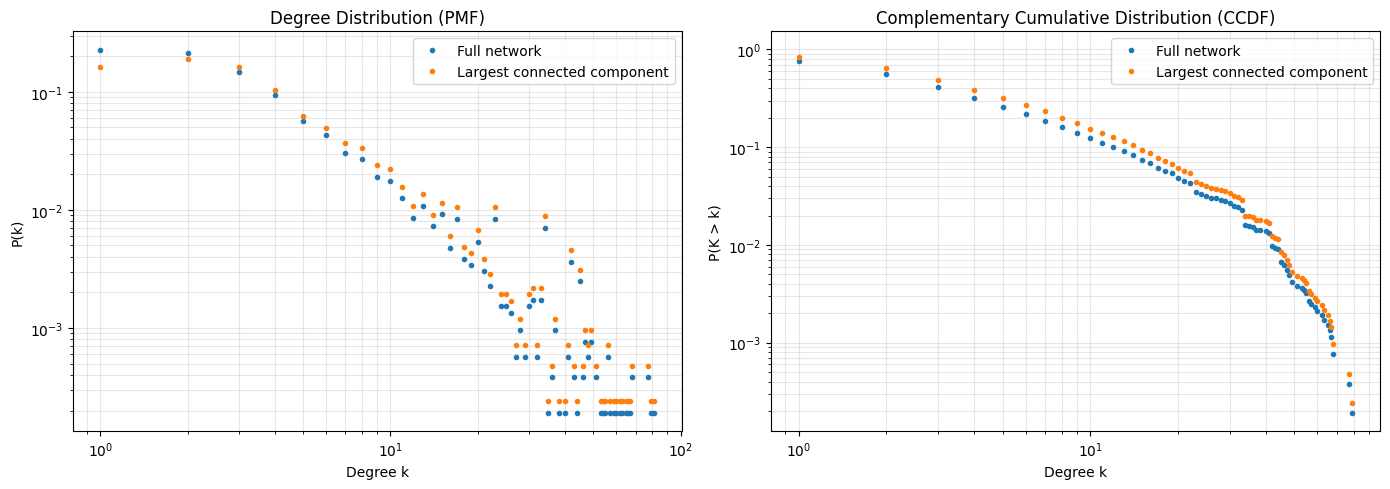

In [11]:
# Create two degree distribution plots

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PMF
for degrees, label in [
    (degrees_full, "Full network"),
    (degrees_lcc, "Largest connected component")
]:

    unique_k, counts = np.unique(
        degrees, return_counts=True
    )

    probabilities = counts / len(degrees)

    axes[0].loglog(
        unique_k,
        probabilities,
        "o",
        markersize=3,
        label=label
    )

axes[0].set_xlabel("Degree k")
axes[0].set_ylabel("P(k)")
axes[0].set_title("Degree Distribution (PMF)")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)


# CCDF
for degrees, label in [
    (degrees_full, "Full network"),
    (degrees_lcc, "Largest connected component")
]:

    sorted_degrees = np.sort(degrees)

    k_values = np.unique(sorted_degrees)

    ccdf = np.array([
        np.mean(degrees > k)
        for k in k_values
    ])

    valid = ccdf > 0

    axes[1].loglog(
        k_values[valid],
        ccdf[valid],
        "o",
        markersize=3,
        label=label
    )

axes[1].set_xlabel("Degree k")
axes[1].set_ylabel("P(K > k)")
axes[1].set_title("Complementary Cumulative Distribution (CCDF)")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()

# Save the figure
plt.savefig(
    os.path.join(FIGURES_DIR, "B1_degree_distributions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The network exhibits characteristics consistent with a heterogeneous, heavy-tailed degree distribution:
- Most researchers have relatively few collaborators.
- A small number of researchers have substantially more collaborators.
- The distribution is asymmetric, with a long right tail.
- The full network and LCC have broadly similar distribution shapes.
But we cannot yet conclude that the network follows a power law.

Fit the power-law distribution

In [12]:
# Remove zero-degree nodes only for power-law fitting

degrees_full_positive = degrees_full[degrees_full > 0]

# LCC already has no zero-degree nodes
degrees_lcc_positive = degrees_lcc[degrees_lcc > 0]

print("Full network:")
print("Original number of nodes:", len(degrees_full))
print("Positive-degree observations:", len(degrees_full_positive))

print("\nLargest connected component:")
print("Positive-degree observations:", len(degrees_lcc_positive))

Full network:
Original number of nodes: 5242
Positive-degree observations: 5241

Largest connected component:
Positive-degree observations: 4158


In [13]:
# Fit power-law distributions

fit_full = powerlaw.Fit(
    degrees_full_positive,
    discrete=True,
    verbose=False
)

fit_lcc = powerlaw.Fit(
    degrees_lcc_positive,
    discrete=True,
    verbose=False
)

# Extract estimated parameters

powerlaw_results = pd.DataFrame({
    "Network": ["Full network", "Largest connected component"],

    "Gamma": [
        fit_full.power_law.alpha,
        fit_lcc.power_law.alpha
    ],

    "Xmin": [
        fit_full.power_law.xmin,
        fit_lcc.power_law.xmin
    ],

    "KS distance": [
        fit_full.power_law.D,
        fit_lcc.power_law.D
    ]
})

display(powerlaw_results)

,Network,Gamma,Xmin,KS distance
0,Full network,2.113465,3.0,0.044102
1,Largest connected component,2.063461,3.0,0.057299


is this a prove that the network follows a power distribution? NO

Let's see how the theoretical distribution compares with the observed degree distribution.

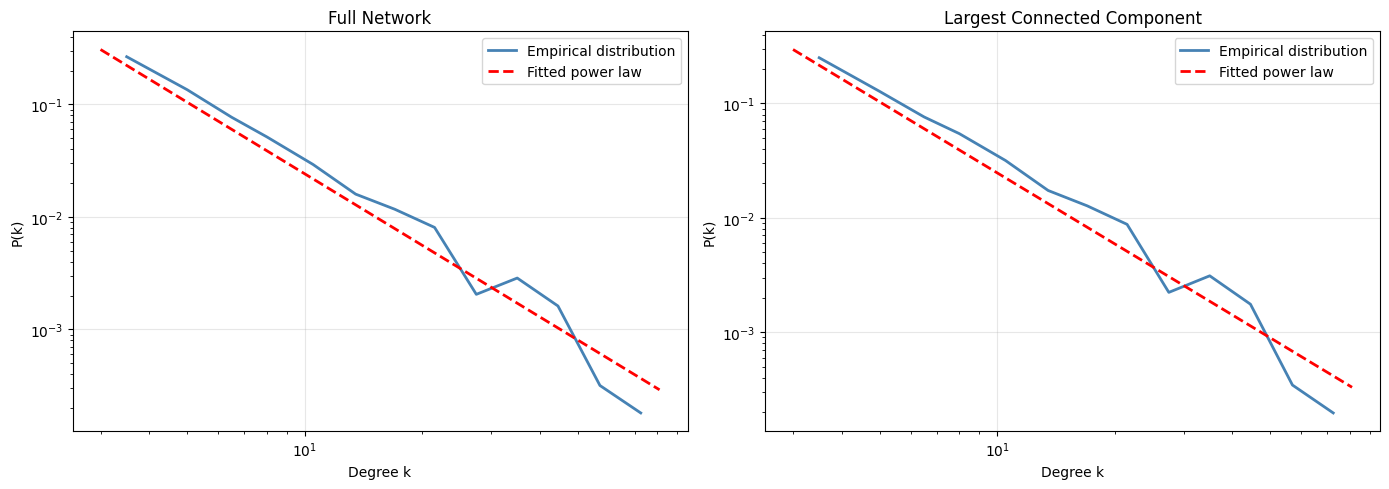

In [14]:
# Plot fitted power-law distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fit_full.plot_pdf(
    ax=axes[0],
    color="steelblue",
    linewidth=2,
    label="Empirical distribution"
)

fit_full.power_law.plot_pdf(
    ax=axes[0],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Fitted power law"
)

axes[0].set_title("Full Network")
axes[0].set_xlabel("Degree k")
axes[0].set_ylabel("P(k)")
axes[0].legend()
axes[0].grid(alpha=0.3)


fit_lcc.plot_pdf(
    ax=axes[1],
    color="steelblue",
    linewidth=2,
    label="Empirical distribution"
)

fit_lcc.power_law.plot_pdf(
    ax=axes[1],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Fitted power law"
)

axes[1].set_title("Largest Connected Component")
axes[1].set_xlabel("Degree k")
axes[1].set_ylabel("P(k)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "B1_powerlaw_fitting.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare the power law with alternative distributions:
two important measures:


R: tells us which distribution is favored.



p: tells us whether the difference is statistically significant under the likelihood-ratio test.

In [17]:
# Compare alternative distributions

def compare_distributions(fit, network_name):

    comparisons = [
        ("power_law", "truncated_power_law", True),
        ("power_law", "lognormal", False),
        ("power_law", "exponential", False)
    ]

    results = []

    for dist1, dist2, is_nested in comparisons:

        R, p = fit.distribution_compare(
            dist1,
            dist2,
            nested=is_nested
        )

        if R > 0:
            favored = dist1
        elif R < 0:
            favored = dist2
        else:
            favored = "Neither"

        if p < 0.05:
            significance = "Significant"
        else:
            significance = "Not significant"

        results.append({
            "Network": network_name,
            "Comparison": f"{dist1} vs {dist2}",
            "R": R,
            "p-value": p,
            "Favored distribution": favored,
            "Significance": significance
        })

    return pd.DataFrame(results)


# Compare models for both networks

comparison_full = compare_distributions(
    fit_full,
    "Full network"
)

comparison_lcc = compare_distributions(
    fit_lcc,
    "Largest connected component"
)

comparison_results = pd.concat(
    [comparison_full, comparison_lcc],
    ignore_index=True
)

display(comparison_results.round(5))

,Network,Comparison,R,p-value,Favored distribution,Significance
0,Full network,power_law vs truncated_power_law,-84.06620,0.0,truncated_power_law,Significant
1,Full network,power_law vs lognormal,-68.50878,0.0,lognormal,Significant
2,Full network,power_law vs exponential,269.36607,0.0,power_law,Significant
3,Largest connected component,power_law vs truncated_power_law,-100.94185,0.0,truncated_power_law,Significant
4,Largest connected component,power_law vs lognormal,-84.32900,0.0,lognormal,Significant
5,Largest connected component,power_law vs exponential,185.25544,0.0,power_law,Significant


save the results

In [18]:
comparison_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B1_distribution_comparisons.csv"
    ),
    index=False
)

print("Distribution comparison results saved!")

Distribution comparison results saved!


The network has a heavy-tailed degree distribution that is better explained by the truncated power law and log-normal than by a pure power law.

However, the pure power law still describes the data better than the exponential distribution.

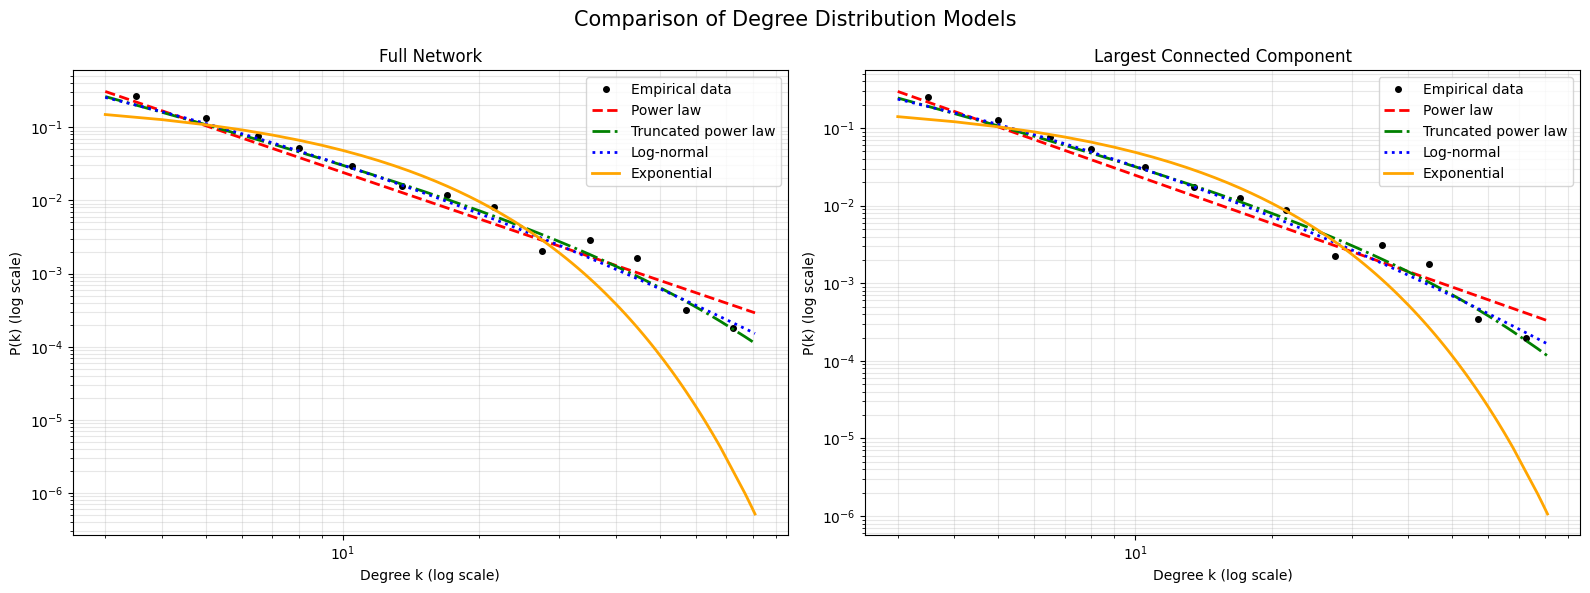

In [19]:
# Compare all four fitted distributions

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

network_fits = [
    (fit_full, "Full Network"),
    (fit_lcc, "Largest Connected Component")
]

for ax, (fit, network_name) in zip(axes, network_fits):

    # Empirical degree distribution
    fit.plot_pdf(
        ax=ax,
        color="black",
        marker="o",
        linestyle="None",
        markersize=4,
        label="Empirical data"
    )

    # Pure power law
    fit.power_law.plot_pdf(
        ax=ax,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Power law"
    )

    # Truncated power law
    fit.truncated_power_law.plot_pdf(
        ax=ax,
        color="green",
        linestyle="-.",
        linewidth=2,
        label="Truncated power law"
    )

    # Log-normal
    fit.lognormal.plot_pdf(
        ax=ax,
        color="blue",
        linestyle=":",
        linewidth=2,
        label="Log-normal"
    )

    # Exponential
    fit.exponential.plot_pdf(
        ax=ax,
        color="orange",
        linestyle="-",
        linewidth=2,
        label="Exponential"
    )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Degree k (log scale)")
    ax.set_ylabel("P(k) (log scale)")
    ax.set_title(network_name)

    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

plt.suptitle(
    "Comparison of Degree Distribution Models",
    fontsize=15
)

plt.tight_layout()

# Save the figure
plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "B1_four_distribution_comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The CA-GrQc network exhibits a heavy-tailed degree distribution, but a pure power law is not the best-supported model.

Both the truncated power law and log-normal distribution are statistically favored over the pure power law.

The exponential distribution performs substantially worse.

In [20]:
# Save power-law fitting parameters

powerlaw_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B1_powerlaw_parameters.csv"
    ),
    index=False
)

# Save likelihood-ratio comparisons
comparison_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B1_distribution_comparisons.csv"
    ),
    index=False
)

print("B1 results saved successfully!")

B1 results saved successfully!


next we are comparing truncated power law against log-normal just by curiosity

In [21]:
# Direct comparison: truncated power law vs log-normal

def compare_truncated_vs_lognormal(fit, network_name):

    R, p = fit.distribution_compare(
        "truncated_power_law",
        "lognormal",
        nested=False
    )

    if R > 0:
        favored = "Truncated power law"
    elif R < 0:
        favored = "Log-normal"
    else:
        favored = "Neither"

    return {
        "Network": network_name,
        "R": R,
        "p-value": p,
        "Favored distribution": favored,
        "Significant": p < 0.05
    }


direct_comparisons = pd.DataFrame([
    compare_truncated_vs_lognormal(
        fit_full, "Full network"
    ),
    compare_truncated_vs_lognormal(
        fit_lcc, "Largest connected component"
    )
])

display(direct_comparisons)

,Network,R,p-value,Favored distribution,Significant
0,Full network,15.557417,9.283915e-11,Truncated power law,True
1,Largest connected component,16.612849,2.157041e-10,Truncated power law,True


This is strong evidence in favor of the truncated power law over the log-normal distribution.

In [22]:
# Save direct comparison results

direct_comparisons.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B1_truncated_vs_lognormal.csv"
    ),
    index=False
)

# Save the final model comparison table
comparison_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B1_distribution_comparisons.csv"
    ),
    index=False
)

# Save the power-law parameters
powerlaw_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "B1_powerlaw_parameters.csv"
    ),
    index=False
)

print("B1 analysis completed and saved!")

B1 analysis completed and saved!
